# Polymarket: Data Inventory and Exploratory Analysis
**Stats C161 · Midterm project preparation · October 18, 2026**

**Main question: What data do we actually have, and how can we use it?**

This notebook inventories the live course database before choosing a project topic. It shows the available tables, every public-schema field, row counts, time coverage, example records, join keys, and data quality. It also imports one complete day of wallet fills and inspects one hour of order-book files.

**Reading order:** Sections 1–4 explain the database; Sections 5–7 explore the data; Sections 8–9 turn the findings into possible project questions. All timestamps are UTC. Saved outputs are a snapshot from the execution time; rerunning queries may change the results.

We retain only this notebook. Remote data are queried or held in memory; no CSV, Parquet download, database file, or chart file is exported.

## At a glance: findings from the saved run

**Snapshot: October 18, 2026.** This orientation summarizes the saved outputs; live counts may change when rerun.

| What we found | Why it matters |
|---|---|
| **1,362,312 markets**, **303,835 events**, **281,663 resolutions** | The catalog is broad enough to explore topics before deciding on one. |
| **5 public tables**, with 55 fields in total | Four analytical schemas plus a wallet-mapping lookup; all fields are listed below. |
| `market_hourly` has **0 rows**; `price_24h_before` has **0 populated values** | There is no ready-made hourly price panel or pre-resolution price feature in these fields. |
| About **84.6%** of markets lack `last_trade_price`; about **84.7%** lack weekly volume | A large catalog does not mean complete numerical features. Missing values are not zeros. |
| All markets are marked active; none marked closed | Stored status flags cannot establish current trading status. |
| The catalog EDA imports **5,346 markets** using a deterministic hash slice | Full-catalog counts/missingness and sample-based charts are clearly separated. |
| The October 17 wallet file has **1,001,870 fills**, **36,849 wallets**, **23,344 market slugs** | Actual trade records support behavior and concentration analysis; 23,334 slugs matched the catalog. |
| The selected hour has **1,264,474 book updates across 200 conditions**; its snapshot covers **30,775 conditions** | Update-stream coverage and snapshot coverage differ substantially in this hour. Do not assume every catalog market has updates. |

The examples include Yes/No, Up/Down, Over/Under, and named-team outcomes. Use the actual labels and join keys rather than assuming every market is a Yes/No question.

## 1. Setup and scope

Run the notebook from top to bottom in a Python 3.9+ kernel. If packages are missing, run the following in a notebook cell, then restart the kernel:

```python
%pip install pandas numpy matplotlib duckdb psycopg2-binary requests
```

The course announcement supplies the same course password for two distinct accounts: the database username includes the project suffix, while the HTTP username does not. Connection settings below follow the October 18 announcement. Access is scheduled through October 29, 2026, 11:59 p.m. PDT.

**Analysis scope:** exact SQL aggregates over four analytical tables; a deterministic hash slice of the market catalog (approximately 1/256 of rows) for plots; all wallet fills on **2026-10-17**; order-book files for **2026-09-29 17:00 UTC**. These fixed file dates support repeatable exploration; they are not claims about the full archive's coverage.

In [1]:
import os
import sys
import base64
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
from psycopg2 import sql
import requests
import duckdb
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 70)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

BASE_URL = "https://d1yyqbluk0oz0t.cloudfront.net"
COURSE_PASSWORD = os.environ.get("POLYMARKET_PASSWORD", "PolymarketData2026!")
TRADE_DATE = "2026-10-17"
BOOK_HOUR = "2026-09-29T17"
RUN_AT = pd.Timestamp.now(tz="UTC")
ANALYTICAL_TABLES = ["events", "markets", "resolutions", "market_hourly"]

versions = {name: importlib.metadata.version(name) for name in
            ["pandas", "numpy", "matplotlib", "duckdb", "psycopg2-binary", "requests"]}
display(pd.Series({"execution_time_utc": RUN_AT.isoformat(), "python": sys.version.split()[0],
                   **versions}, name="runtime").to_frame())

Matplotlib is building the font cache; this may take a moment.


/private/tmp/stats161-midterm-runtime/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


,runtime
execution_time_utc,2026-10-18T20:07:36.633561+00:00
python,3.9.6
pandas,2.3.3
numpy,2.0.2
matplotlib,3.9.4
duckdb,1.4.5
psycopg2-binary,2.9.12
requests,2.32.5


In [2]:
# PostgreSQL: server-side read-only session. The helper returns pandas DataFrames.
pg = psycopg2.connect(
    host="aws-0-us-west-2.pooler.supabase.com", port=6543, dbname="postgres",
    user="polymarketdatabase.merbqatlxbrcvtbnuaqe", password=COURSE_PASSWORD,
    sslmode="require", connect_timeout=20,
)
pg.set_session(readonly=True, autocommit=True)
with pg.cursor() as cur:
    cur.execute("SET TIME ZONE 'UTC'")
    cur.execute("SET statement_timeout = '120s'")

def ask(query, params=None):
    with pg.cursor() as cur:
        cur.execute(query, params)
        return pd.DataFrame(cur.fetchall(), columns=[column.name for column in cur.description])

# DuckDB is an in-memory engine for the remote Parquet files.
db = duckdb.connect(":memory:")
if os.environ.get("STATS161_DUCKDB_EXTENSION_DIR"):
    db.execute("SET extension_directory = ?", [os.environ["STATS161_DUCKDB_EXTENSION_DIR"]])
db.execute("INSTALL httpfs; LOAD httpfs;")
db.execute("SET TimeZone = 'UTC'; SET threads = 4; SET memory_limit = '1GB';")
db.execute("SET http_timeout = 30")
authorization = "Basic " + base64.b64encode(
    f"polymarketdatabase:{COURSE_PASSWORD}".encode()
).decode()
db.execute(f"""
    CREATE SECRET course_http (
        TYPE HTTP, SCOPE '{BASE_URL}',
        EXTRA_HTTP_HEADERS MAP {{'Authorization': '{authorization}'}}
    )
""")

def book(query, params=None):
    return db.execute(query, params or []).df()

http = requests.Session()
http.auth = ("polymarketdatabase", COURSE_PASSWORD)
display(ask("SELECT current_timestamp AS database_time_utc, current_setting('transaction_read_only') AS read_only"))

,database_time_utc,read_only
0,2026-10-18 20:07:37.378979+00:00,on


## 2. What is available?

The SQL connection exposes both public project tables and extension-maintenance views. The HTTP endpoint serves known Parquet paths; it does not provide a browsable archive listing.

| Source | Unit of observation | Main content | Identifier used for joins |
|---|---|---|---|
| `events` | One event | Title, description, scheduled dates, status and sync fields | `events.slug` |
| `markets` | One market/question | Outcome labels and token IDs, latest stored quotes, volume and liquidity | `markets.slug`, `condition_id`, `event_slug` |
| `resolutions` | One resolved market | Winning binary label, final price, resolution timestamp | `market_slug → markets.slug` |
| `market_hourly` | Intended market-hour | OHLC, volume, trade count; check actual population below | `market_slug`, `hour` |
| `wallet_pseudonym_map` | Internal lookup | Wallet pseudonym mapping; schema listed, row contents not needed for this analysis | Use the supplied pseudonyms in trade files |
| `wallet_trades/trades-YYYY-MM-DD.parquet` | One recorded fill | Pseudonymous wallet, market, side, outcome, time, price, shares, dollars | `market → markets.slug` |
| `events-YYYY-MM-DDTHH.parquet` | One order-book level update | Timestamp, token, condition, side, price, new level size | `market → markets.condition_id`; `asset_id → token_ids` |
| `snap-YYYY-MM-DDTHH.parquet` | One token's hourly book snapshot | Lists of resting bid and ask levels | Same condition/token identifiers as deltas |

**Naming trap:** SQL `events` means a catalog of events. An `events-*.parquet` file contains order-book updates. In addition, the `market` field in wallet files is a **slug**, while the identically named field in order-book files is a **condition ID**.

In [3]:
visible_tables = ask("""
    SELECT table_schema, table_name, table_type
    FROM information_schema.tables
    WHERE table_schema NOT IN ('pg_catalog', 'information_schema')
    ORDER BY table_schema, table_name
""")
display(visible_tables)

inventory_rows = []
for table in ANALYTICAL_TABLES:
    count_query = sql.SQL("SELECT count(*) AS n_rows FROM public.{}").format(sql.Identifier(table))
    inventory_rows.append({"table": table, "exact_row_count": int(ask(count_query).iloc[0, 0])})
table_inventory = pd.DataFrame(inventory_rows)
display(table_inventory)
display(Markdown("The wallet mapping table is inventoried through its schema only. Extension views are maintenance metadata, not market observations."))

,table_schema,table_name,table_type
0,extensions,pg_stat_statements,VIEW
1,extensions,pg_stat_statements_info,VIEW
2,public,events,BASE TABLE
3,public,market_hourly,BASE TABLE
4,public,markets,BASE TABLE
5,public,resolutions,BASE TABLE
6,public,wallet_pseudonym_map,BASE TABLE


,table,exact_row_count
0,events,303835
1,markets,1362312
2,resolutions,281663
3,market_hourly,0


The wallet mapping table is inventoried through its schema only. Extension views are maintenance metadata, not market observations.

### 2.1 Complete public-schema data dictionary

Types and nullability below are read live from `information_schema`. The **meaning** column is an explanation based on the supplied guide and observed field names, not a database constraint. A nullable field may still be populated; Section 4 measures actual missingness.

`markets.synced_at` is stored as Unix **seconds**. Order-book `ts_ms` uses Unix **milliseconds**. The other timestamp fields already carry a timezone.

In [4]:
schema = ask("""
    SELECT table_name, ordinal_position, column_name, data_type, udt_name, is_nullable
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""")
common_meanings = {
    "slug": "Unique catalog identifier", "title": "Human-readable question or event title",
    "start_date": "Scheduled opening/start time", "end_date": "Scheduled ending time; not necessarily actual resolution",
    "active": "Stored status flag; validate before filtering", "closed": "Stored status flag; validate before filtering",
    "archived": "Stored archive flag", "neg_risk": "Negative-risk / mutually exclusive outcome structure flag",
    "created_at": "Creation timestamp", "updated_at": "Source update timestamp", "synced_at": "Catalog synchronization time",
    "market_slug": "Market identifier, joins to markets.slug",
}
field_meanings = {
    "events": {"ticker": "Event ticker", "description": "Free-text event description"},
    "markets": {
        "condition_id": "Condition identifier used by order-book files",
        "synced_at": "Catalog synchronization time as Unix seconds",
        "resolution_source": "Source used to decide the market outcome",
        "enable_order_book": "Whether an order book is enabled",
        "last_trade_price": "Latest stored token trade price; use outcome labels to interpret",
        "best_bid": "Latest stored highest bid", "best_ask": "Latest stored lowest ask",
        "volume_clob": "Stored cumulative CLOB trading volume", "liquidity_clob": "Stored CLOB liquidity measure",
        "volume_24hr": "Stored rolling 24-hour volume", "volume_1wk": "Stored rolling weekly volume",
        "volume_1mo": "Stored rolling monthly volume", "token_ids": "Array of token identifiers, paired by position with outcomes",
        "outcomes": "Array of outcome labels; not always Yes/No", "event_slug": "Parent event, joins to events.slug",
    },
    "resolutions": {
        "resolved_yes": "Recorded Yes-versus-No resolution label; verify label semantics for non-Yes/No markets",
        "price_at_close": "Final first-token price, typically near 0 or 1; post-outcome information",
        "price_24h_before": "Intended pre-resolution price; check population below",
        "resolved_at": "Recorded closing/resolution time; guide notes scheduled-end fallback when source close time is missing",
        "uma_resolution_status": "UMA status supplied at synchronization; may be missing",
    },
    "market_hourly": {
        "hour": "UTC hour", "open": "First hourly price", "high": "Highest hourly price", "low": "Lowest hourly price",
        "close": "Last hourly price", "volume": "Hourly volume", "trade_count": "Hourly trade count",
    },
    "wallet_pseudonym_map": {
        "real_wallet": "Internal source-wallet lookup key (binary)",
        "pseudo_wallet": "Internal pseudonymous-wallet lookup value (binary)",
    },
}
schema["meaning"] = [field_meanings.get(t, {}).get(c, common_meanings.get(c, "See source documentation"))
                     for t, c in zip(schema.table_name, schema.column_name)]
for table, fields in schema.groupby("table_name", sort=False):
    display(Markdown(f"**`{table}` — {len(fields)} fields**"))
    display(fields[["column_name", "data_type", "is_nullable", "meaning"]].reset_index(drop=True))

**`events` — 13 fields**

,column_name,data_type,is_nullable,meaning
0,slug,text,NO,Unique catalog identifier
1,ticker,text,YES,Event ticker
2,title,text,NO,Human-readable question or event title
3,description,text,YES,Free-text event description
4,start_date,timestamp with time zone,YES,Scheduled opening/start time
5,end_date,timestamp with time zone,YES,Scheduled ending time; not necessarily actual resolution
6,active,boolean,YES,Stored status flag; validate before filtering
7,closed,boolean,YES,Stored status flag; validate before filtering
8,archived,boolean,YES,Stored archive flag
9,neg_risk,boolean,YES,Negative-risk / mutually exclusive outcome structure flag


**`market_hourly` — 8 fields**

,column_name,data_type,is_nullable,meaning
0,market_slug,text,NO,"Market identifier, joins to markets.slug"
1,hour,timestamp with time zone,NO,UTC hour
2,open,numeric,YES,First hourly price
3,high,numeric,YES,Highest hourly price
4,low,numeric,YES,Lowest hourly price
5,close,numeric,YES,Last hourly price
6,volume,numeric,YES,Hourly volume
7,trade_count,integer,YES,Hourly trade count


**`markets` — 25 fields**

,column_name,data_type,is_nullable,meaning
0,slug,text,NO,Unique catalog identifier
1,title,text,NO,Human-readable question or event title
2,condition_id,text,YES,Condition identifier used by order-book files
3,synced_at,bigint,NO,Catalog synchronization time as Unix seconds
4,start_date,timestamp with time zone,YES,Scheduled opening/start time
5,end_date,timestamp with time zone,YES,Scheduled ending time; not necessarily actual resolution
6,active,boolean,YES,Stored status flag; validate before filtering
7,closed,boolean,YES,Stored status flag; validate before filtering
8,archived,boolean,YES,Stored archive flag
9,created_at,timestamp with time zone,YES,Creation timestamp


**`resolutions` — 6 fields**

,column_name,data_type,is_nullable,meaning
0,market_slug,text,NO,"Market identifier, joins to markets.slug"
1,resolved_yes,boolean,NO,Recorded Yes-versus-No resolution label; verify label semantics for non-Yes/No markets
2,price_at_close,numeric,NO,"Final first-token price, typically near 0 or 1; post-outcome information"
3,price_24h_before,numeric,YES,Intended pre-resolution price; check population below
4,resolved_at,timestamp with time zone,YES,Recorded closing/resolution time; guide notes scheduled-end fallback when source close time is m...
5,uma_resolution_status,text,YES,UMA status supplied at synchronization; may be missing


**`wallet_pseudonym_map` — 3 fields**

,column_name,data_type,is_nullable,meaning
0,real_wallet,bytea,NO,Internal source-wallet lookup key (binary)
1,pseudo_wallet,bytea,NO,Internal pseudonymous-wallet lookup value (binary)
2,created_at,timestamp with time zone,NO,Creation timestamp


### 2.2 Declared keys and relationships

The query below uses PostgreSQL's constraint catalog. `p` is a primary key, `f` is a foreign key, and `u` is a uniqueness constraint. A declared relationship does not replace a measured join-coverage check.

```text
events.slug <──────── markets.event_slug
                         │
                         ├─ slug <──────── resolutions.market_slug
                         ├─ slug <──────── market_hourly.market_slug
                         ├─ slug <──────── wallet_trades.market
                         ├─ condition_id <─ order_book.market
                         └─ token_ids[i] <─ order_book.asset_id
                            outcomes[i] identifies that token's outcome
```

In [5]:
constraints = ask("""
    SELECT c.relname AS table_name, p.contype AS kind,
           pg_get_constraintdef(p.oid) AS definition, p.convalidated AS validated
    FROM pg_constraint p
    JOIN pg_class c ON c.oid = p.conrelid
    JOIN pg_namespace n ON n.oid = c.relnamespace
    WHERE n.nspname = 'public'
    ORDER BY table_name, kind
""")
display(constraints)
join_coverage = ask("""
    SELECT count(*) AS markets,
           count(m.event_slug) AS nonnull_event_slug,
           count(e.slug) AS matching_event,
           count(r.market_slug) AS matching_resolution,
           count(*) FILTER (WHERE m.event_slug IS NOT NULL AND e.slug IS NULL) AS unmatched_event_reference
    FROM markets m
    LEFT JOIN events e ON e.slug = m.event_slug
    LEFT JOIN resolutions r ON r.market_slug = m.slug
""")
display(join_coverage)

,table_name,kind,definition,validated
0,events,p,PRIMARY KEY (slug),True
1,market_hourly,f,FOREIGN KEY (market_slug) REFERENCES markets(slug),True
2,market_hourly,p,"PRIMARY KEY (market_slug, hour)",True
3,markets,f,FOREIGN KEY (event_slug) REFERENCES events(slug),True
4,markets,p,PRIMARY KEY (slug),True
5,resolutions,f,FOREIGN KEY (market_slug) REFERENCES markets(slug),True
6,resolutions,p,PRIMARY KEY (market_slug),True
7,wallet_pseudonym_map,p,PRIMARY KEY (real_wallet),True
8,wallet_pseudonym_map,u,UNIQUE (pseudo_wallet),True


,markets,nonnull_event_slug,matching_event,matching_resolution,unmatched_event_reference
0,1362312,1362308,1362308,281663,0


## 3. What do the actual records look like?

These are **previews**, selected by identifier, not representative statistical samples. The market preview includes every original field. A later section imports a reproducible catalog slice for EDA.

In [6]:
for table in ANALYTICAL_TABLES:
    order_by = {"events": "slug", "markets": "slug", "resolutions": "market_slug", "market_hourly": "hour"}[table]
    query = sql.SQL("SELECT * FROM public.{} ORDER BY {} LIMIT 3").format(
        sql.Identifier(table), sql.Identifier(order_by))
    preview = ask(query)
    display(Markdown(f"**`{table}` preview**"))
    display(preview.T if table == "markets" else preview)

**`events` preview**

,slug,ticker,title,description,start_date,end_date,active,closed,archived,neg_risk,created_at,updated_at,synced_at
0,0-ships-transit-hormuz-on-any-date-byptpt-20260626172559966,0-ships-transit-hormuz-on-any-date-byptpt-20260626172559966,0 ships transit Hormuz on any date by..?,This market will resolve to “Yes” if IMF PortWatch publishes a daily number of transit calls (“A...,2026-06-26 18:44:58.805392+00:00,2026-07-31 23:59:00+00:00,True,False,False,False,2026-06-26 18:28:46.703909+00:00,2026-07-17 17:15:20.051020+00:00,2026-10-18 11:27:56+00:00
1,1-box-office-this-weekend,1-box-office-this-weekend,#1 Box Office This Weekend?,This market will resolve according to which film earns the highest domestic box office gross for...,2026-09-23 22:09:46+00:00,2026-09-27 12:00:00+00:00,True,False,False,True,2026-09-23 22:09:25.332562+00:00,2026-09-24 00:16:48.549206+00:00,2026-10-18 11:27:56+00:00
2,1-free-app-in-the-us-apple-app-store-on-august-14-20260807163527162,1-free-app-in-the-us-apple-app-store-on-august-14-20260807163527162,#1 Free App in the US Apple App Store on August 14?,"This market will resolve according to the iOS app, ranked #1 in the United States on the iPhone ...",2026-08-07 22:57:54.289845+00:00,2026-08-14 23:59:00+00:00,True,False,False,True,2026-08-07 22:54:36.433027+00:00,2026-08-09 05:15:57.366930+00:00,2026-10-18 11:27:56+00:00


**`markets` preview**

,0,1,2
slug,0-ships-transit-hormuz-on-any-date-by-august-31,0-ships-transit-hormuz-on-any-date-by-july-14-20260626172559969,0-ships-transit-hormuz-on-any-date-by-october-31
title,0 ships transit Hormuz on any date by August 31?,0 ships transit Hormuz on any date by July 14?,0 ships transit Hormuz on any date by October 31?
condition_id,0xab38d355b9733ce4d605d47f6643436c1d706889efcb922682bf2e1d7c795bec,0x88ce0bfc46c66e6cbd22c3eef83dea8a3dc393741aa756c12a99ecdd6bc50441,0x1bb5b249f4c286c9955a4719b912794a8d82c48509fa0e775f8974570fd77025
synced_at,1792322334,1792322334,1792322334
start_date,2026-07-29 16:30:28.215047+00:00,2026-06-26 20:30:32.319987+00:00,2026-09-03 13:01:18+00:00
end_date,2026-09-01 03:59:00+00:00,2026-07-14 23:59:00+00:00,2026-11-01 03:59:00+00:00
active,True,True,True
closed,False,False,False
archived,False,False,False
created_at,2026-07-29 16:27:35.206236+00:00,2026-06-26 18:28:47.205808+00:00,2026-09-03 13:00:51.563257+00:00


**`resolutions` preview**

,market_slug,resolved_yes,price_at_close,price_24h_before,resolved_at,uma_resolution_status
0,0-ships-transit-hormuz-on-any-date-by-july-14-20260626172559969,False,0.0,None,2026-07-21 19:16:15+00:00,resolved
1,1-free-app-in-the-us-apple-app-store-on-october-2-20260925t180000000z-will-muse-from-meta-be-1-f...,True,1.0,None,2026-10-02 18:04:02+00:00,resolved
2,1-free-app-in-the-us-apple-app-store-on-september-25-20260918t180000000z-will-chatgpt-be-1-free-...,False,0.0,None,2026-09-25 18:04:35+00:00,resolved


**`market_hourly` preview**

,market_slug,hour,open,high,low,close,volume,trade_count


### 3.1 Time coverage, synchronization, and status fields

Catalog start/end dates describe market lifetimes. They are not a guarantee that historical prices exist for those dates. Stored quotes and rolling volumes are snapshots from each row's synchronization time. The catalog is live and successive queries can observe different updates.

In [7]:
market_coverage = ask("""
    SELECT count(*) AS n_markets, count(DISTINCT condition_id) AS distinct_condition_ids,
           min(start_date) AS first_scheduled_start, max(start_date) AS last_scheduled_start,
           min(end_date) AS first_scheduled_end, max(end_date) AS last_scheduled_end,
           to_timestamp(min(synced_at)) AS earliest_row_sync,
           to_timestamp(max(synced_at)) AS latest_row_sync,
           count(*) FILTER (WHERE active) AS flagged_active,
           count(*) FILTER (WHERE closed) AS flagged_closed,
           count(*) FILTER (WHERE end_date < current_timestamp) AS past_scheduled_end,
           count(*) FILTER (WHERE end_date >= current_timestamp) AS future_scheduled_end,
           count(*) FILTER (WHERE volume_1wk > 0) AS positive_stored_weekly_volume
    FROM markets
""")
event_coverage = ask("""
    SELECT min(start_date) AS first_scheduled_start, max(end_date) AS last_scheduled_end,
           min(synced_at) AS earliest_row_sync, max(synced_at) AS latest_row_sync
    FROM events
""")
resolution_coverage = ask("""
    SELECT count(*) AS n_resolutions, min(resolved_at) AS earliest_resolution,
           max(resolved_at) AS latest_resolution,
           count(*) FILTER (WHERE resolved_yes) AS recorded_yes_wins,
           count(price_24h_before) AS populated_price_24h_before,
           count(*) FILTER (WHERE price_at_close <= 0.01 OR price_at_close >= 0.99) AS near_terminal_close_prices
    FROM resolutions
""")
display(Markdown("**Markets**")); display(market_coverage.T)
display(Markdown("**Events**")); display(event_coverage.T)
display(Markdown("**Resolutions**")); display(resolution_coverage.T)
row = market_coverage.iloc[0]
display(Markdown(
    f"There are **{int(row.past_scheduled_end):,}** markets past their scheduled end, "
    f"but **{int(row.flagged_active):,}** are flagged active and **{int(row.flagged_closed):,}** flagged closed. "
    "Use these fields as stored metadata, not verified live trading status. A future end date is only a candidate filter; "
    "a resolution record provides stronger evidence of settlement."
))

**Markets**

,0
n_markets,1362312
distinct_condition_ids,1362219
first_scheduled_start,2025-05-02 15:48:10.582000+00:00
last_scheduled_start,2026-10-18 19:18:46.605068+00:00
first_scheduled_end,2025-10-31 00:00:00+00:00
last_scheduled_end,2030-07-22 03:59:00+00:00
earliest_row_sync,2026-09-12 16:17:55+00:00
latest_row_sync,2026-10-18 19:17:46+00:00
flagged_active,1362312
flagged_closed,0


**Events**

,0
first_scheduled_start,2024-12-31 18:51:45.506005+00:00
last_scheduled_end,2030-01-01 04:59:00+00:00
earliest_row_sync,2026-09-12 21:00:37+00:00
latest_row_sync,2026-10-18 19:17:50+00:00


**Resolutions**

,0
n_resolutions,281663
earliest_resolution,2026-01-25 04:59:00+00:00
latest_resolution,2026-10-18 19:59:53.283934+00:00
recorded_yes_wins,91521
populated_price_24h_before,0
near_terminal_close_prices,281663


There are **1,251,601** markets past their scheduled end, but **1,362,312** are flagged active and **0** flagged closed. Use these fields as stored metadata, not verified live trading status. A future end date is only a candidate filter; a resolution record provides stronger evidence of settlement.

## 4. Data quality across the analytical SQL tables

Missingness is computed over **all rows** in each analytical table. Empty tables have no meaningful missingness percentage. The following checks also separate missing values, zeros, invalid ranges, and empty arrays: these are different conditions.

In [8]:
missing_rows = []
for table in ANALYTICAL_TABLES:
    fields = schema.loc[schema.table_name.eq(table), "column_name"].tolist()
    expressions = [sql.SQL("count(*) AS total_rows")]
    expressions += [sql.SQL("count({}) AS {}").format(sql.Identifier(field), sql.Identifier(field)) for field in fields]
    query = sql.SQL("SELECT {} FROM public.{}").format(sql.SQL(", ").join(expressions), sql.Identifier(table))
    counts = ask(query).iloc[0]
    total = int(counts["total_rows"])
    for field in fields:
        missing = total - int(counts[field])
        missing_rows.append({"table": table, "field": field, "n_rows": total,
                             "missing": missing, "missing_pct": 100 * missing / total if total else np.nan})
missingness = pd.DataFrame(missing_rows)
display(missingness.sort_values(["table", "missing_pct"], ascending=[True, False]).reset_index(drop=True))

,table,field,n_rows,missing,missing_pct
0,events,start_date,303835,8622,2.837724
1,events,updated_at,303835,611,0.201096
2,events,end_date,303835,313,0.103016
3,events,ticker,303835,50,0.016456
4,events,slug,303835,0,0.000000
5,events,title,303835,0,0.000000
6,events,description,303835,0,0.000000
7,events,active,303835,0,0.000000
8,events,closed,303835,0,0.000000
9,events,archived,303835,0,0.000000


,0
price_out_of_range,0
quote_out_of_range,0
crossed_quote,0
locked_quote,0
negative_size_measure,0
zero_stored_weekly_volume,55756
scheduled_start_after_end,3708
empty_token_or_outcome_array,0
token_outcome_length_mismatch,0


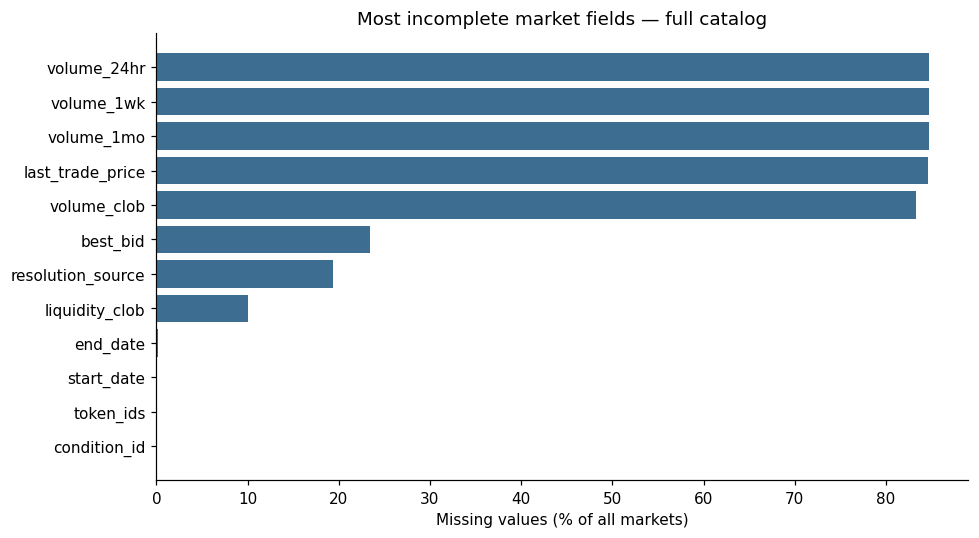

In [9]:
catalog_checks = ask("""
    SELECT count(*) FILTER (WHERE last_trade_price < 0 OR last_trade_price > 1) AS price_out_of_range,
           count(*) FILTER (WHERE best_bid < 0 OR best_bid > 1 OR best_ask < 0 OR best_ask > 1) AS quote_out_of_range,
           count(*) FILTER (WHERE best_bid > best_ask) AS crossed_quote,
           count(*) FILTER (WHERE best_bid = best_ask) AS locked_quote,
           count(*) FILTER (WHERE volume_clob < 0 OR volume_1wk < 0 OR liquidity_clob < 0) AS negative_size_measure,
           count(*) FILTER (WHERE volume_1wk = 0) AS zero_stored_weekly_volume,
           count(*) FILTER (WHERE start_date > end_date) AS scheduled_start_after_end,
           count(*) FILTER (WHERE token_ids = '[]'::jsonb OR outcomes = '[]'::jsonb) AS empty_token_or_outcome_array,
           count(*) FILTER (WHERE jsonb_array_length(token_ids) <> jsonb_array_length(outcomes)) AS token_outcome_length_mismatch
    FROM markets
""")
display(catalog_checks.T)
fig, ax = plt.subplots(figsize=(9, 5))
plot_missing = missingness.query("table == 'markets'").sort_values("missing_pct").tail(12)
ax.barh(plot_missing.field, plot_missing.missing_pct, color="#3d6d91")
ax.set(xlabel="Missing values (% of all markets)", title="Most incomplete market fields — full catalog")
plt.tight_layout(); plt.show()

## 5. Import a reproducible catalog slice and perform EDA

The catalog contains over a million markets. Rather than pulling every row into pandas, we select slugs whose MD5 hash starts with `00` (approximately **1/256** of identifiers). This is deterministic and independent of an explicit topic filter, but it is not a designed stratified sample. All plots in this section refer only to this slice.

We join event titles and resolution information for context. Current catalog values are **not historical predictors at the resolution date**. No predictive model is fitted in this inventory notebook.

In [10]:
market_sample = ask("""
    SELECT m.*, e.title AS event_title,
           r.resolved_yes, r.resolved_at, r.price_at_close
    FROM markets m
    LEFT JOIN events e ON e.slug = m.event_slug
    LEFT JOIN resolutions r ON r.market_slug = m.slug
    WHERE left(md5(m.slug), 2) = '00'
    ORDER BY m.slug
""")
numeric_fields = ["last_trade_price", "best_bid", "best_ask", "volume_clob", "liquidity_clob",
                  "volume_24hr", "volume_1wk", "volume_1mo", "price_at_close"]
for field in numeric_fields:
    market_sample[field] = pd.to_numeric(market_sample[field], errors="coerce")
for field in ["start_date", "end_date", "created_at", "updated_at", "resolved_at"]:
    market_sample[field] = pd.to_datetime(market_sample[field], utc=True)
market_sample["sync_time"] = pd.to_datetime(market_sample.synced_at, unit="s", utc=True)
market_sample["spread"] = market_sample.best_ask - market_sample.best_bid
market_sample["scheduled_duration_days"] = (market_sample.end_date - market_sample.start_date).dt.total_seconds() / 86400
market_sample["outcome_labels"] = market_sample.outcomes.map(lambda x: " / ".join(x) if isinstance(x, list) else "missing")
display(Markdown(f"Imported **{len(market_sample):,} market rows** with all catalog fields and linked event/resolution context."))
display(market_sample[["slug", "title", "event_title", "outcome_labels", "last_trade_price", "volume_1wk"]].head(10))
display(market_sample[numeric_fields + ["spread", "scheduled_duration_days"]].describe(percentiles=[.5, .9, .99]).T)

Imported **5,346 market rows** with all catalog fields and linked event/resolution context.

,slug,title,event_title,outcome_labels,last_trade_price,volume_1wk
0,2-spotify-song-in-the-us-this-week-october-9-20261002t140000000z-will-patient-zero-taylor-swift-...,"Will ""Patient Zero - Taylor Swift"" be the #2 US song this week?",#2 Spotify song in the US this week? (October 9),Yes / No,NaN,NaN
1,2026-bank-of-utah-championship-winner-justin-lower-win,Will Justin Lower win the 2026 Bank of Utah Championship?,PGA Tour: Bank of Utah Championship Winner,Yes / No,NaN,NaN
2,2026-biltmore-championship-asheville-first-round-leader-ben-kohles,Will Ben Kohles lead the 2026 Biltmore Championship Asheville following the first round?,PGA Tour: Biltmore Championship Asheville First Round Leader,Yes / No,NaN,NaN
3,2026-biltmore-championship-asheville-top20-jeremy-paul,Will Jeremy Paul finish in the Top 20 at the 2026 Biltmore Championship Asheville?,PGA Tour: Biltmore Championship Asheville Top 20,Yes / No,NaN,NaN
4,2026-biltmore-championship-asheville-top20-matthieu-pavon,Will Matthieu Pavon finish in the Top 20 at the 2026 Biltmore Championship Asheville?,PGA Tour: Biltmore Championship Asheville Top 20,Yes / No,NaN,NaN
5,2026-charles-schwab-challenge-top10-rasmus-neergaard-petersen,Will Rasmus Neergaard-Petersen finish in the Top 10 at the 2026 Charles Schwab Challenge?,PGA Tour: Charles Schwab Challenge Top 10,Yes / No,NaN,NaN
6,2026-charles-schwab-challenge-top20-justin-thomas,Will Justin Thomas finish in the Top 20 at the 2026 Charles Schwab Challenge?,PGA Tour: Charles Schwab Challenge Top 20,Yes / No,0.48,NaN
7,2026-charles-schwab-challenge-top20-mark-hubbard,Will Mark Hubbard finish in the Top 20 at the 2026 Charles Schwab Challenge?,PGA Tour: Charles Schwab Challenge Top 20,Yes / No,NaN,NaN
8,2026-mlb-win-totals-new-york-yankees,Will the New York Yankees win more than 86.5 games in the 2026 MLB Regular Season?,MLB: 2026 Regular Season Win Totals,O 86.5 / U 86.5,0.78,14.38
9,2026-rbc-canadian-open-top10-ze-cheng-dou,Will Ze-Cheng Dou finish in the Top 10 at the 2026 RBC Canadian Open?,PGA Tour: RBC Canadian Open Top 10,Yes / No,NaN,NaN


,count,mean,std,min,50%,90%,99%,max
last_trade_price,800.0,0.301011,0.345436,0.000000,0.150000,0.990000,0.999000,9.990000e-01
best_bid,4146.0,0.170639,0.257888,0.000000,0.020000,0.500000,0.999000,9.990000e-01
best_ask,5346.0,0.754336,0.330937,0.001000,0.980000,1.000000,1.000000,1.000000e+00
volume_clob,855.0,24032.877344,360824.666469,0.000000,117.751112,5940.872095,231430.669080,9.797924e+06
liquidity_clob,4819.0,4677.874671,31103.023881,0.000000,30.300000,3813.887240,106191.612513,1.026813e+06
volume_24hr,786.0,3235.112239,31876.311871,0.000000,50.000000,2241.635914,50652.742131,8.188922e+05
volume_1wk,786.0,4429.775317,36727.707195,0.000000,70.572307,2888.521219,81215.257855,8.188922e+05
volume_1mo,786.0,7501.765014,79009.218105,0.000000,72.522890,3369.739480,102958.268696,1.468436e+06
price_at_close,1072.0,0.331157,0.470849,0.000000,0.000000,1.000000,1.000000,1.000000e+00
spread,4146.0,0.599665,0.437828,0.001000,0.940000,0.980000,1.000000,1.000000e+00


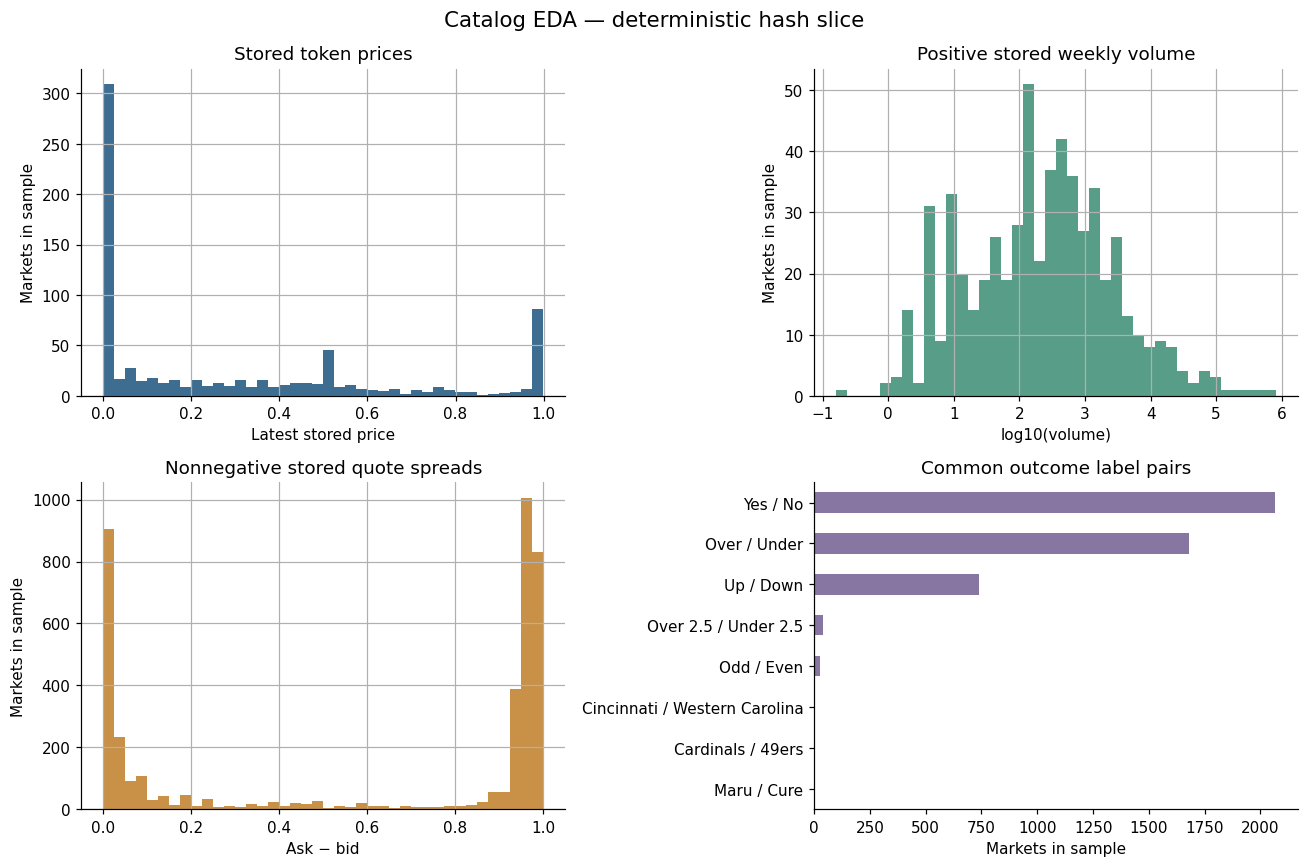

**Interpretation:** Prices near 0 or 1 can reflect long shots, completed markets, or stale stored values. They do not by themselves establish forecast accuracy. Zero weekly volume is excluded only from the log-volume panel; the full-catalog zero count is reported above. Outcome labels must be checked before interpreting a price as P(Yes).

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
market_sample.last_trade_price.dropna().hist(bins=40, ax=axes[0, 0], color="#3d6d91")
axes[0, 0].set(title="Stored token prices", xlabel="Latest stored price", ylabel="Markets in sample")
positive_volume = market_sample.loc[market_sample.volume_1wk.gt(0), "volume_1wk"]
np.log10(positive_volume).hist(bins=40, ax=axes[0, 1], color="#589d87")
axes[0, 1].set(title="Positive stored weekly volume", xlabel="log10(volume)", ylabel="Markets in sample")
valid_spread = market_sample.loc[market_sample.spread.between(0, 1), "spread"]
valid_spread.hist(bins=40, ax=axes[1, 0], color="#c89147")
axes[1, 0].set(title="Nonnegative stored quote spreads", xlabel="Ask − bid", ylabel="Markets in sample")
market_sample.outcome_labels.value_counts().head(8).sort_values().plot.barh(ax=axes[1, 1], color="#8876a2")
axes[1, 1].set(title="Common outcome label pairs", xlabel="Markets in sample", ylabel="")
fig.suptitle("Catalog EDA — deterministic hash slice", fontsize=14)
plt.tight_layout(); plt.show()
display(Markdown(
    "**Interpretation:** Prices near 0 or 1 can reflect long shots, completed markets, or stale stored values. "
    "They do not by themselves establish forecast accuracy. Zero weekly volume is excluded only from the log-volume panel; "
    "the full-catalog zero count is reported above. Outcome labels must be checked before interpreting a price as P(Yes)."
))

### 5.1 Browse potential topics without choosing one

There is no explicit category/topic field in the observed public schema. A title keyword search is a **discovery tool**, not a validated category classifier. Change `KEYWORD` to inspect a subject, or browse event titles and descriptions. Ranking by stored weekly volume does not establish current activity.

,title,event_title,outcomes,last_trade_price,volume_1wk,start_date,end_date,sync_time,resolved_at
0,"MicroStrategy sells any Bitcoin by May 31, 2026?",MicroStrategy sells any Bitcoin by ___ ?,"[Yes, No]",0.001,28096965.24497602,2026-05-05 23:48:20.102000+00:00,2026-07-01 04:00:00+00:00,2026-10-18 11:18:54+00:00,2026-06-04 00:34:19+00:00
1,"MicroStrategy sells any Bitcoin by June 30, 2026?",MicroStrategy sells any Bitcoin by ___ ?,"[Yes, No]",0.999,2867644.333077004,2025-11-19 22:51:30.483000+00:00,2026-07-01 04:00:00+00:00,2026-10-18 11:18:54+00:00,2026-06-01 14:07:11+00:00
2,"Will Bitcoin reach $85,000 in May?",What price will Bitcoin hit in May?,"[Yes, No]",0.001,1506621.4393809997,2026-05-01 14:39:25.558418+00:00,2026-06-01 04:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
3,"Will the price of Bitcoin be above $66,000 on June 3?",Bitcoin above ___ on June 3?,"[Yes, No]",0.999,1233724.8493449995,2026-05-27 16:04:12.923026+00:00,2026-06-03 16:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
4,"Will Bitcoin reach $90,000 in May?",What price will Bitcoin hit in May?,"[Yes, No]",0.001,1189294.26374,2026-05-01 14:40:37.904395+00:00,2026-06-01 04:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
5,"Will the price of Bitcoin be above $64,000 on June 4?",Bitcoin above ___ on June 4?,"[Yes, No]",0.001,779938.2095089993,2026-05-28 16:02:38.462000+00:00,2026-06-04 16:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
6,"Will Bitcoin dip to $60,000 in June?",What price will Bitcoin hit in June?,"[Yes, No]",0.66,772388.9496440013,2026-06-01 14:40:40.456000+00:00,2026-07-01 04:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
7,"Will Bitcoin dip to $65,000 in May?",What price will Bitcoin hit in May?,"[Yes, No]",0.003,747063.6392199999,2026-05-01 14:41:16.382000+00:00,2026-06-01 04:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
8,"MicroStrategy sells any Bitcoin by December 31, 2026?",MicroStrategy sells any Bitcoin by ___ ?,"[Yes, No]",0.997,679612.899955999,2025-12-04 21:46:05.703000+00:00,2027-01-01 05:00:00+00:00,2026-10-18 11:18:54+00:00,NaT
9,"Will the price of Bitcoin be above $68,000 on June 5?",Bitcoin above ___ on June 5?,"[Yes, No]",0.002,667420.95041,2026-05-29 16:04:51.811000+00:00,2026-06-05 16:00:00+00:00,2026-10-18 11:18:54+00:00,NaT


,month,resolved_markets,recorded_yes_wins
0,2026-01-01 00:00:00+00:00,1,0
1,2026-05-01 00:00:00+00:00,2423,739
2,2026-06-01 00:00:00+00:00,34470,12100
3,2026-07-01 00:00:00+00:00,6506,2086
4,2026-08-01 00:00:00+00:00,14506,4840
5,2026-09-01 00:00:00+00:00,127581,45570
6,2026-10-01 00:00:00+00:00,96176,26186


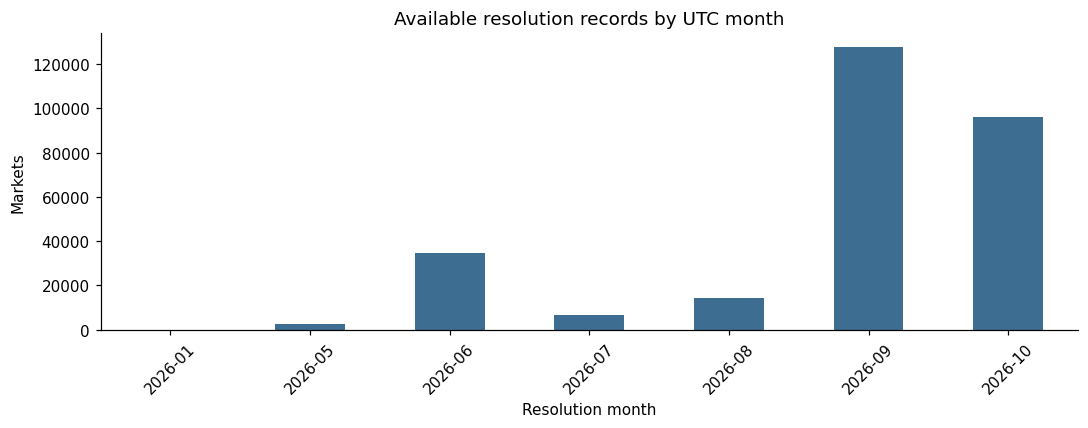

In [12]:
KEYWORD = "bitcoin"
topic_preview = ask("""
    SELECT m.title, e.title AS event_title, m.outcomes, m.last_trade_price,
           m.volume_1wk, m.start_date, m.end_date, to_timestamp(m.synced_at) AS sync_time,
           r.resolved_at
    FROM markets m
    LEFT JOIN events e ON e.slug = m.event_slug
    LEFT JOIN resolutions r ON r.market_slug = m.slug
    WHERE m.title ILIKE %s
    ORDER BY m.volume_1wk DESC NULLS LAST, m.slug
    LIMIT 15
""", (f"%{KEYWORD}%",))
display(topic_preview)

resolution_months = ask("""
    SELECT date_trunc('month', resolved_at) AS month,
           count(*) AS resolved_markets,
           count(*) FILTER (WHERE resolved_yes) AS recorded_yes_wins
    FROM resolutions WHERE resolved_at IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")
display(resolution_months)
monthly_plot = resolution_months.assign(month_label=pd.to_datetime(resolution_months.month).dt.strftime("%Y-%m"))
ax = monthly_plot.set_index("month_label").resolved_markets.plot.bar(color="#3d6d91", rot=45)
ax.set(title="Available resolution records by UTC month", xlabel="Resolution month", ylabel="Markets")
plt.tight_layout(); plt.show()

## 6. What is in the remote files?

The endpoint root does not expose a directory listing. We check **specific documented paths and selected dates** with authenticated HEAD requests. A successful probe proves that one file exists; missing probes and historical gaps must not be interpreted as a complete archive inventory.

The guide reports order-book capture starting May 30, 2026, with recorder gaps on June 16–19, August 25–31, and September 14. Its wallet-coverage statement ends October 5, but the later selected date is tested below. We do not claim continuous coverage between probes.

In [13]:
file_paths = [
    "events-2026-05-30T21.parquet",
    f"events-{BOOK_HOUR}.parquet", f"snap-{BOOK_HOUR}.parquet",
    "wallet_trades/trades-2026-10-03.parquet",
    "wallet_trades/trades-2026-10-05.parquet",
    f"wallet_trades/trades-{TRADE_DATE}.parquet",
]
probe_rows = []
for path in dict.fromkeys(file_paths):
    response = http.head(f"{BASE_URL}/{path}", timeout=30, allow_redirects=False)
    length = response.headers.get("Content-Length")
    probe_rows.append({"path": path, "http_status": response.status_code,
                       "file_size_MiB": int(length) / 1024**2 if length else np.nan})
file_inventory = pd.DataFrame(probe_rows)
display(file_inventory)

TRADE_URL = f"{BASE_URL}/wallet_trades/trades-{TRADE_DATE}.parquet"
DELTA_URL = f"{BASE_URL}/events-{BOOK_HOUR}.parquet"
SNAP_URL = f"{BASE_URL}/snap-{BOOK_HOUR}.parquet"
for label, url in [("Wallet fills", TRADE_URL), ("Order-book deltas", DELTA_URL), ("Order-book snapshot", SNAP_URL)]:
    display(Markdown(f"**{label}: observed Parquet schema**"))
    display(book("DESCRIBE SELECT * FROM read_parquet(?)", [url])[["column_name", "column_type"]])
    display(book("SELECT count(*) AS n_rows FROM read_parquet(?)", [url]))

,path,http_status,file_size_MiB
0,events-2026-05-30T21.parquet,200,220.521447
1,events-2026-09-29T17.parquet,200,10.044230
2,snap-2026-09-29T17.parquet,200,12.373953
3,wallet_trades/trades-2026-10-03.parquet,200,17.914884
4,wallet_trades/trades-2026-10-05.parquet,200,8.231453
5,wallet_trades/trades-2026-10-17.parquet,200,19.821685


**Wallet fills: observed Parquet schema**

,column_name,column_type
0,wallet,VARCHAR
1,market,VARCHAR
2,time,TIMESTAMP WITH TIME ZONE
3,side,VARCHAR
4,outcome,VARCHAR
5,price,DOUBLE
6,size,DOUBLE
7,dollars,DOUBLE


,n_rows
0,1001870


**Order-book deltas: observed Parquet schema**

,column_name,column_type
0,ts_ms,BIGINT
1,asset_id,VARCHAR
2,market,VARCHAR
3,side,VARCHAR
4,price,DOUBLE
5,size,DOUBLE


,n_rows
0,1264474


**Order-book snapshot: observed Parquet schema**

,column_name,column_type
0,ts_ms,BIGINT
1,asset_id,VARCHAR
2,market,VARCHAR
3,bids,"STRUCT(price DOUBLE, size DOUBLE)[]"
4,asks,"STRUCT(price DOUBLE, size DOUBLE)[]"


,n_rows
0,61370


### 6.1 Import one complete day of wallet fills

The full selected day is loaded into an **in-memory DuckDB table**. We move small previews and aggregates into pandas. `size` is shares; `dollars` is recorded fill value; `side` is BUY/SELL for the recorded wallet; `outcome` names the token traded. Wallet IDs are stable pseudonyms across files.

Summed `dollars` describes the recorded rows. Without a documented deduplication/counterparty convention, it should not be called unique exchange-wide turnover. A single day's trading is also insufficient to compute a wallet's lifetime profit or identify an insider.

In [14]:
db.execute("CREATE TEMP TABLE trade_day AS SELECT * FROM read_parquet(?)", [TRADE_URL])
trade_preview = book("SELECT * FROM trade_day ORDER BY time, market, wallet LIMIT 8")
trade_summary = book("""
    SELECT count(*) AS n_fills, count(DISTINCT wallet) AS n_wallets,
           count(DISTINCT market) AS n_markets,
           min(time) AS first_fill_utc, max(time) AS last_fill_utc,
           sum(dollars) AS recorded_fill_dollars,
           min(price) AS min_price, max(price) AS max_price
    FROM trade_day
""")
trade_quality = book("""
    SELECT count(*) FILTER (WHERE wallet IS NULL OR market IS NULL OR time IS NULL) AS missing_identifiers_or_time,
           count(*) FILTER (WHERE price IS NULL OR size IS NULL OR dollars IS NULL) AS missing_numeric_values,
           count(*) FILTER (WHERE price < 0 OR price > 1) AS price_out_of_range,
           count(*) FILTER (WHERE size < 0 OR dollars < 0) AS negative_size_or_dollars,
           count(*) FILTER (WHERE CAST(time AS DATE) <> CAST(? AS DATE)) AS fills_outside_filename_date,
           count(*) FILTER (WHERE abs(dollars - price * size) > 0.011) AS dollar_share_price_discrepancies
    FROM trade_day
""", [TRADE_DATE])
display(trade_summary.T); display(trade_preview); display(trade_quality.T)
display(book("SELECT side, outcome, count(*) AS n_fills FROM trade_day GROUP BY 1,2 ORDER BY n_fills DESC LIMIT 15"))

,0
n_fills,1001870
n_wallets,36849
n_markets,23344
first_fill_utc,2026-10-17 00:00:00+00:00
last_fill_utc,2026-10-17 23:59:59+00:00
recorded_fill_dollars,81161919.885952
min_price,0.001
max_price,0.999


,wallet,market,time,side,outcome,price,size,dollars
0,0x38daab3edd4400db9335f6bee09bcd6ee201b1b9,btc-updown-5m-1792194900,2026-10-17 00:00:00+00:00,SELL,Down,0.999000,42.540000,42.49746
1,0xe41e6c21540796e0cc43c680f69da9cc35165a1a,btc-updown-5m-1792195200,2026-10-17 00:00:00+00:00,BUY,Down,0.450000,4.444445,2.00000
2,0xb73be06da617714a70c0f40b267db57d64379803,canpl-sup-int-2026-10-16-int,2026-10-17 00:00:00+00:00,BUY,No,0.930000,72.698914,67.60999
3,0x4f17af2c914a79150a5a09d1e190350551530920,eth-updown-5m-1792195200,2026-10-17 00:00:00+00:00,BUY,Up,0.596087,92.000000,54.84000
4,0xedfae167719d88ba6fefa08de6fcc1b0082006e3,sol-updown-5m-1792195200,2026-10-17 00:00:00+00:00,SELL,Down,0.450000,9.000000,4.05000
5,0xb5a9e4a9368e6620efd528eb1b1865f1a3b5c0a3,ufc-suy-cod12-2026-10-17,2026-10-17 00:00:00+00:00,BUY,Cody Chovancek,0.540000,37.037038,20.00000
6,0x75d3796d1964c4db99c3e104b6a538514db81dc8,will-shakhtar-donetsk-win-the-2026-27-uefa-champions-league-championship-20260701202025578,2026-10-17 00:00:00+00:00,BUY,Yes,0.002000,5.000000,0.01000
7,0x110c07f047fa874a5a2cc7171e2ff6f9417e3b07,bra2-rec-fec-2026-10-16-fec,2026-10-17 00:00:02+00:00,BUY,Yes,0.280000,142.857143,40.00000


,0
missing_identifiers_or_time,0
missing_numeric_values,0
price_out_of_range,0
negative_size_or_dollars,0
fills_outside_filename_date,0
dollar_share_price_discrepancies,0


,side,outcome,n_fills
0,BUY,Yes,171703
1,BUY,Up,170720
2,BUY,Down,164121
3,BUY,No,114478
4,SELL,Yes,32059
5,BUY,Under,29785
6,SELL,Up,28813
7,BUY,Over,25021
8,SELL,Down,24931
9,SELL,No,23606


In [15]:
wallet_activity = book("""
    SELECT wallet, count(*) AS n_fills, count(DISTINCT market) AS n_markets,
           sum(dollars) AS recorded_fill_dollars,
           min(time) AS first_fill_utc, max(time) AS last_fill_utc
    FROM trade_day GROUP BY wallet ORDER BY recorded_fill_dollars DESC
""")
market_activity = book("""
    SELECT market, count(*) AS n_fills, count(DISTINCT wallet) AS n_wallets,
           sum(dollars) AS recorded_fill_dollars
    FROM trade_day GROUP BY market ORDER BY recorded_fill_dollars DESC
""")
hourly_activity = book("""
    SELECT date_trunc('hour', time) AS hour_utc, count(*) AS n_fills,
           sum(dollars) AS recorded_fill_dollars
    FROM trade_day GROUP BY 1 ORDER BY 1
""")
trade_slugs = market_activity.market.tolist()
trade_catalog = ask("SELECT slug, title, event_slug, outcomes FROM markets WHERE slug = ANY(%s)", (trade_slugs,))
market_activity = market_activity.merge(trade_catalog, left_on="market", right_on="slug", how="left", validate="one_to_one")
display(Markdown(f"**{market_activity.title.notna().sum():,}/{len(market_activity):,} traded market slugs matched the catalog.**"))
display(market_activity[["title", "market", "n_fills", "n_wallets", "recorded_fill_dollars"]].head(12))
display(wallet_activity.head(8))

**23,334/23,344 traded market slugs matched the catalog.**

,title,market,n_fills,n_wallets,recorded_fill_dollars
0,Counter-Strike: Team Falcons vs BetBoom Team (BO3) - Thunderpick World Championship Playoffs,cs2-fal2-bb3-2026-10-17,3787,1240,1.661113e+06
1,Will FC Barcelona win on 2026-10-17?,lal-bet-bar-2026-10-17-bar,4573,1576,1.533698e+06
2,Will Manchester City FC win on 2026-10-17?,epl-mac-ips-2026-10-17-mac,2868,1245,1.101947e+06
3,LoL: MVK Esports vs FURIA Esports - Game 3 Winner,lol-mvk-fur-2026-10-17-game3,3931,1060,1.051647e+06
4,Will AS Roma win on 2026-10-17?,sea-rom-gen-2026-10-17-rom,2095,999,1.044298e+06
5,LoL: MVK Esports vs FURIA Esports - Game 4 Winner,lol-mvk-fur-2026-10-17-game4,2967,882,9.907827e+05
6,LoL: MVK Esports vs FURIA Esports - Game 2 Winner,lol-mvk-fur-2026-10-17-game2,3199,978,9.098057e+05
7,Ohio State vs. Indiana,cfb-ohiost-ind-2026-10-17,1310,433,8.959961e+05
8,Wuhan Tennis Open: Iga Swiatek vs Maja Chwalinska,wta-swiatek-chwalin-2026-10-17,2868,549,8.212435e+05
9,LoL: BNK FEARX vs Team WE - Game 3 Winner,lol-fox1-we-2026-10-17-game3,3245,918,7.973684e+05


,wallet,n_fills,n_markets,recorded_fill_dollars,first_fill_utc,last_fill_utc
0,0xb73be06da617714a70c0f40b267db57d64379803,28473,3638,4.189521e+06,2026-10-17 00:00:00+00:00,2026-10-17 23:59:45+00:00
1,0xe0446ec594b827d5934e11420318d307e327337f,22593,3500,3.584962e+06,2026-10-17 00:00:11+00:00,2026-10-17 23:59:44+00:00
2,0x77024bd3a9178330d38c08ef01a768f1a3a5a866,797,282,1.522703e+06,2026-10-17 00:08:12+00:00,2026-10-17 23:51:47+00:00
3,0x510dbb2de5757595b5603c777be052a937732b27,203,84,1.238133e+06,2026-10-17 00:00:33+00:00,2026-10-17 23:51:35+00:00
4,0x8c6fde0b3efe66c932a495da7f8ac3683e2f6b15,6222,629,9.088425e+05,2026-10-17 00:00:21+00:00,2026-10-17 23:59:50+00:00
5,0xa2f6721e782dd03a11432057704163739630dc32,52,6,8.669073e+05,2026-10-17 14:30:36+00:00,2026-10-17 21:08:44+00:00
6,0xb41ca8fc37252cc1f2a807309a38ccccfcf3a4b4,58,12,7.931481e+05,2026-10-17 15:27:44+00:00,2026-10-17 22:18:08+00:00
7,0xa90bbcddd21ef5b76d6b2cf2fc023061334dd005,21,9,7.056630e+05,2026-10-17 07:24:36+00:00,2026-10-17 23:25:44+00:00


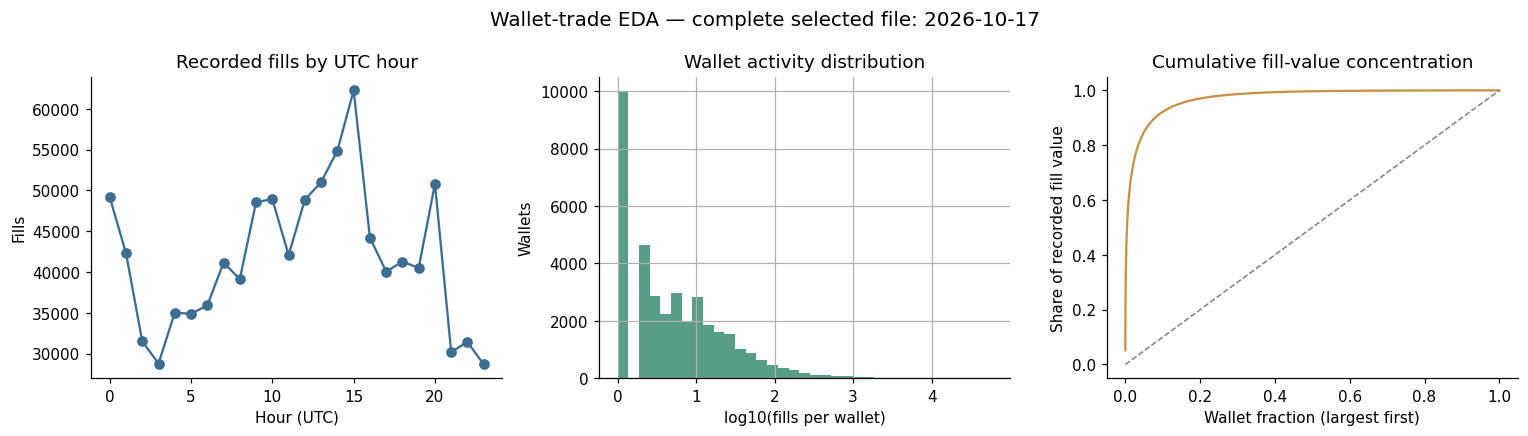

In this file, the largest **369** wallets (about 1% of wallets with positive fill value) account for **62.0%** of recorded fill value. This describes concentration, not evidence of informed trading.

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(hourly_activity.hour_utc.dt.hour, hourly_activity.n_fills, marker="o", color="#3d6d91")
axes[0].set(title="Recorded fills by UTC hour", xlabel="Hour (UTC)", ylabel="Fills")
np.log10(wallet_activity.n_fills).hist(bins=35, ax=axes[1], color="#589d87")
axes[1].set(title="Wallet activity distribution", xlabel="log10(fills per wallet)", ylabel="Wallets")
positive_wallets = wallet_activity.loc[wallet_activity.recorded_fill_dollars.gt(0)].copy()
positive_wallets["cum_share"] = positive_wallets.recorded_fill_dollars.cumsum() / positive_wallets.recorded_fill_dollars.sum()
axes[2].plot(np.arange(1, len(positive_wallets) + 1) / len(positive_wallets), positive_wallets.cum_share, color="#c89147")
axes[2].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[2].set(title="Cumulative fill-value concentration", xlabel="Wallet fraction (largest first)", ylabel="Share of recorded fill value")
fig.suptitle(f"Wallet-trade EDA — complete selected file: {TRADE_DATE}", fontsize=13)
plt.tight_layout(); plt.show()
top_n = max(1, int(np.ceil(len(positive_wallets) * .01)))
top_share = positive_wallets.head(top_n).recorded_fill_dollars.sum() / positive_wallets.recorded_fill_dollars.sum()
display(Markdown(f"In this file, the largest **{top_n:,}** wallets (about 1% of wallets with positive fill value) account for **{top_share:.1%}** of recorded fill value. This describes concentration, not evidence of informed trading."))

## 7. What do order-book data contain?

**Deltas are not trades.** A delta's `size` is the new resting quantity at a price level, not an executed quantity and not a quantity increment. A zero size removes that level. A snapshot contains nested arrays of resting bids and asks.

For a historical book at time T, start from a valid snapshot and apply deltas in timestamp and original file-row order. The course walkthrough documents stale snapshots and book resets. This inventory inspects schemas, coverage and examples; it does not assume that an unvalidated reconstruction is accurate.

In [17]:
db.execute("CREATE TEMP TABLE book_deltas AS SELECT * FROM read_parquet(?)", [DELTA_URL])
delta_summary = book("""
    SELECT count(*) AS n_level_updates, count(DISTINCT market) AS n_conditions,
           count(DISTINCT asset_id) AS n_tokens,
           epoch_ms(min(ts_ms)) AS first_update_utc, epoch_ms(max(ts_ms)) AS last_update_utc,
           count(*) FILTER (WHERE size = 0) AS level_removals,
           count(*) FILTER (WHERE size < 0 OR price < 0 OR price > 1) AS invalid_price_or_size
    FROM book_deltas
""")
snapshot_summary = book("""
    SELECT count(*) AS n_token_snapshots, count(DISTINCT market) AS n_conditions,
           epoch_ms(min(ts_ms)) AS first_snapshot_utc,
           epoch_ms(max(ts_ms)) AS last_snapshot_utc,
           count(*) FILTER (WHERE len(bids) = 0 AND len(asks) = 0) AS empty_both_sides,
           avg(len(bids)) AS mean_bid_levels, avg(len(asks)) AS mean_ask_levels
    FROM read_parquet(?)
""", [SNAP_URL])
display(delta_summary.T); display(snapshot_summary.T)
display(book("SELECT * FROM book_deltas LIMIT 5"))
display(book("""
    SELECT ts_ms, asset_id, market, len(bids) AS n_bid_levels, len(asks) AS n_ask_levels,
           list_slice(bids, 1, 3) AS first_three_bids,
           list_slice(asks, 1, 3) AS first_three_asks
    FROM read_parquet(?) WHERE len(bids) > 0 AND len(asks) > 0 LIMIT 3
""", [SNAP_URL]))

,0
n_level_updates,1264474
n_conditions,200
n_tokens,400
first_update_utc,2026-09-29 17:00:00.057000
last_update_utc,2026-09-29 17:59:59.997000
level_removals,173356
invalid_price_or_size,0


,0
n_token_snapshots,61370
n_conditions,30775
first_snapshot_utc,2026-09-29 17:00:00
last_snapshot_utc,2026-09-29 17:00:00
empty_both_sides,25304
mean_bid_levels,12.795975
mean_ask_levels,12.799316


,ts_ms,asset_id,market,side,price,size
0,1790701200057,71677612305244936641085500097737038199081845621961106192204236262687669821119,0xaece8d6062d3e3eb9845b32441a4ab06eb2ef332c0228bc6a36add450647c7c4,BUY,0.969,25.00
1,1790701200057,73197441127256680134600821323583356037261213281680365433623681075249556019477,0xaece8d6062d3e3eb9845b32441a4ab06eb2ef332c0228bc6a36add450647c7c4,SELL,0.031,25.00
2,1790701200059,71677612305244936641085500097737038199081845621961106192204236262687669821119,0xaece8d6062d3e3eb9845b32441a4ab06eb2ef332c0228bc6a36add450647c7c4,BUY,0.969,25.00
3,1790701200059,73197441127256680134600821323583356037261213281680365433623681075249556019477,0xaece8d6062d3e3eb9845b32441a4ab06eb2ef332c0228bc6a36add450647c7c4,SELL,0.031,25.00
4,1790701200091,113287701564209339913693347405685749986285999146352375265161592243948562084773,0x307a1ed89d60b61002dd5bbf00e1408c5ed2ab3fcdb056191ca7ef9bc34d38f3,BUY,0.620,70644.64


,ts_ms,asset_id,market,n_bid_levels,n_ask_levels,first_three_bids,first_three_asks
0,1790701200000,40932864651005132434669457369564353816786330205469778285035893634458129671101,0xc586d15be76278848a26c761c2fcf70f8cebca71815cfab83e656ff5c6ec13a9,4,72,"[{'price': 0.004, 'size': 2287.32}, {'price': 0.003, 'size': 168738.25}, {'price': 0.002, 'size'...","[{'price': 0.006, 'size': 22491.45}, {'price': 0.007, 'size': 98653.93}, {'price': 0.008, 'size'..."
1,1790701200000,56215025902031889702122383201324191240581604266667334383154318117703136383150,0xc586d15be76278848a26c761c2fcf70f8cebca71815cfab83e656ff5c6ec13a9,72,4,"[{'price': 0.994, 'size': 22491.45}, {'price': 0.993, 'size': 98653.93}, {'price': 0.992, 'size'...","[{'price': 0.996, 'size': 2287.32}, {'price': 0.997, 'size': 168738.25}, {'price': 0.998, 'size'..."
2,1790701200000,4045735984349668080431454492320197927729985255084840663280469559927680162929,0x05f77d169919fe7b1125d832b6d347f628bc5c0b93d2bb408ecba68b22158310,54,8,"[{'price': 0.99, 'size': 520.0}, {'price': 0.989, 'size': 576.64}, {'price': 0.988, 'size': 1481...","[{'price': 0.991, 'size': 1717.49}, {'price': 0.992, 'size': 500.0}, {'price': 0.993, 'size': 70..."


In [18]:
busy_conditions = book("""
    SELECT market AS condition_id, count(*) AS n_level_updates,
           count(DISTINCT asset_id) AS n_tokens
    FROM book_deltas GROUP BY market ORDER BY n_level_updates DESC LIMIT 10
""")
book_catalog = ask("""
    SELECT condition_id, slug, title, outcomes, token_ids
    FROM markets WHERE condition_id = ANY(%s)
""", (busy_conditions.condition_id.tolist(),))
book_join = busy_conditions.merge(book_catalog, on="condition_id", how="left")
display(book_join[["title", "condition_id", "n_level_updates", "n_tokens", "outcomes"]])

# Keep token identifiers as strings; casting them to floats loses precision.
token_lookup = []
for row in book_catalog.itertuples():
    if isinstance(row.outcomes, list) and isinstance(row.token_ids, list):
        token_lookup.extend({"market_slug": row.slug, "outcome": label, "asset_id": str(token)}
                            for label, token in zip(row.outcomes, row.token_ids))
display(pd.DataFrame(token_lookup).head(10))

,title,condition_id,n_level_updates,n_tokens,outcomes
0,"Will Elon Musk post <40 tweets from September 28 to September 30, 2026?",0x59d9d029939ed129fefffb3a394c852aa9cff1fe5fed663ba96ad75dae9c4172,55160,2,"[Yes, No]"
1,Will Magdalena Andersson be the next Prime Minister of Sweden?,0x58d5cc2bf06a3289b127049239aee051f3b941f219efebbca02d3f50f0eb2a64,52276,2,"[Yes, No]"
2,Will the Democrats win the Maine Senate race in 2026?,0x66bbf6d55e0296278858b3147689f3df9259374f158f9f028b608baa322a639c,44348,2,"[Yes, No]"
3,Will Parti Québécois win the most seats in the 2026 Quebec general election?,0x30d4a64f70d80faee66508a797b347ef65e63913e4200bca954718fc824ea10e,43928,2,"[Yes, No]"
4,Will the Republicans win the Maine Senate race in 2026?,0x2c00cb09722a0f0501c5e49131b898ed57bb5c075db4dc2bcbc14908f45b8c48,39044,2,"[Yes, No]"
5,Will Ulrich Siegmund be the next Minister-President of Sachsen-Anhalt?,0x87335e877a46e289636d66bda62f4e950dd2e3b63ade63ed8481b34c06349b1a,33980,2,"[Yes, No]"
6,Will Gadi Eizenkot be the next Prime Minister of Israel?,0xdbe93b5a701f36076a560fa4b9ba59e365a6e8e2ea6a83764640010657277ca4,32640,2,"[Yes, No]"
7,"Will Elon Musk post 160-179 tweets from September 25 to October 2, 2026?",0xc6b88d783895e29bd1e486a11b03a86bc94f3fdcb5d3729e7b430ccd8ff347f1,28892,2,"[Yes, No]"
8,Iran-Oman Hormuz Agreement by September 30?,0xde64f0c49c7b26baa1ed2ebb7097574de5532c2237b779ab9b415e822c12a0a0,26648,2,"[Yes, No]"
9,Will Luiz Inácio Lula da Silva win the 2026 Brazilian presidential election?,0xdf8e2dc5860027decbe6164555c3c1c9645c3bd33e16b9dc57ca87125047d4a8,25596,2,"[Yes, No]"


,market_slug,outcome,asset_id
0,will-the-republicans-win-the-maine-senate-race-in-2026,Yes,2142948285506077695096498341598672159464223074468931276310105532825810210121
1,will-the-republicans-win-the-maine-senate-race-in-2026,No,43295283577056639281694071578249936735369407445693289764095672178175084599787
2,will-parti-qubcois-win-the-most-seats-in-the-2026-quebec-general-election,Yes,65322106850459544646271115791218393848695885094753222820688299472048959196589
3,will-parti-qubcois-win-the-most-seats-in-the-2026-quebec-general-election,No,104003951685118099617273681901030817359395321307025897997858344751070270175696
4,will-magdalena-andersson-be-the-next-prime-minister-of-sweden,Yes,6761884778816083542753350539779617201084594664234729655783875952381923983097
5,will-magdalena-andersson-be-the-next-prime-minister-of-sweden,No,49952287244614575734723913757649087902024339238007187585607375183859292977482
6,elon-musk-of-tweets-september-28-september-30-2026-0-39,Yes,95894482604133259739236666736954462665552440278797056954214491923228448732944
7,elon-musk-of-tweets-september-28-september-30-2026-0-39,No,111651942445590798478019686908638372618579830479734859343619434053962415135429
8,will-the-democrats-win-the-maine-senate-race-in-2026,Yes,7589880081658059374445882095611024032084645048848237404312287942463647821549
9,will-the-democrats-win-the-maine-senate-race-in-2026,No,6136336712352911156426560180855478229745540927722899997193789497766196705020


## 8. What is usable now, and what is missing?

The table below combines measured availability with the practical implication for a project. Re-run it if the database changes.

In [19]:
counts_by_table = table_inventory.set_index("table").exact_row_count.to_dict()
availability = pd.DataFrame([
    {"data": "Market catalog", "observed": f"{counts_by_table['markets']:,} rows; full schema and missingness inspected",
     "project_use": "Question discovery, market/event features, linking all sources"},
    {"data": "Event catalog", "observed": f"{counts_by_table['events']:,} rows, including descriptions",
     "project_use": "Event grouping and text-based discovery; no explicit category column"},
    {"data": "Resolution labels", "observed": f"{counts_by_table['resolutions']:,} rows",
     "project_use": "Potential outcomes; verify binary-token semantics and prediction cutoff"},
    {"data": "Hourly OHLC table", "observed": f"{counts_by_table['market_hourly']:,} rows",
     "project_use": "Unavailable if empty; derive validated historical features from raw files instead"},
    {"data": "Price 24 hours before resolution", "observed": f"{int(resolution_coverage.iloc[0].populated_price_24h_before):,} populated values",
     "project_use": "Cannot use as a ready-made pre-resolution feature if unpopulated"},
    {"data": "Wallet fills", "observed": f"{int(trade_summary.iloc[0].n_fills):,} recorded fills on {TRADE_DATE}",
     "project_use": "Wallet/market activity, concentration, time-of-day patterns; extend dates for longitudinal analysis"},
    {"data": "Order-book updates", "observed": f"{int(delta_summary.iloc[0].n_level_updates):,} updates in selected hour",
     "project_use": "Liquidity, spread, depth and price dynamics after reconstruction checks"},
])
display(availability)

,data,observed,project_use
0,Market catalog,"1,362,312 rows; full schema and missingness inspected","Question discovery, market/event features, linking all sources"
1,Event catalog,"303,835 rows, including descriptions",Event grouping and text-based discovery; no explicit category column
2,Resolution labels,"281,663 rows",Potential outcomes; verify binary-token semantics and prediction cutoff
3,Hourly OHLC table,0 rows,Unavailable if empty; derive validated historical features from raw files instead
4,Price 24 hours before resolution,0 populated values,Cannot use as a ready-made pre-resolution feature if unpopulated
5,Wallet fills,"1,001,870 recorded fills on 2026-10-17","Wallet/market activity, concentration, time-of-day patterns; extend dates for longitudinal analysis"
6,Order-book updates,"1,264,474 updates in selected hour","Liquidity, spread, depth and price dynamics after reconstruction checks"


### Interpretation limits to carry into any project

- **Status and freshness:** `active`/`closed` may be stale. Scheduled end, resolution records, synchronization time and actual trading evidence answer different questions.
- **Historical labels versus features:** final close price and current catalog snapshots can reveal information unavailable at the intended forecast time. Use strictly earlier features when predicting outcomes.
- **Outcome semantics:** some tokens represent named teams or other labels. Do not silently call the first outcome “Yes.” Inspect `outcomes` and the resolution-label construction before supervised modeling.
- **Coverage:** successful file probes establish individual files, not a continuous date range. Recorder gaps and stale snapshots can invalidate historical-book features.
- **Time aggregation:** the latest resolution month is partial, and absent months in the chart mean no available records in this table, not proof that the platform had no markets.
- **Selection:** catalog plots use the hash slice; wallet aggregates cover one day; book aggregates cover one hour. They describe different populations and dates.
- **Wallet interpretation:** pseudonyms support grouping across files. High volume, concentration, or unusual activity alone does not establish insider trading. A single day does not give complete positions, realized profit, or causal evidence.

## 9. Possible directions to discuss after reading the inventory

These are candidate questions, not selected topics or findings.

| Candidate question | Data needed | Reasonable next step |
|---|---|---|
| How does liquidity relate to spread and update activity? | Validated order-book snapshots/deltas plus catalog context | Compare a baseline with a regression model across markets/hours |
| Are there distinct wallet activity patterns? | Several daily wallet files | Construct activity features, explore PCA/clustering, assess stability across days |
| Does trading activity before settlement help predict the eventual outcome? | Time-stamped fills/books joined to resolutions | Verify token labels, define a fixed prediction horizon, use time-based validation and a baseline |

For now, the deliverable is a map of available data. Choose a question only after checking its sample size, historical coverage, label meaning and evaluation plan.

### Sources

- [Course syllabus](../C161%20C262%20Syllabus.pdf): project context and presentation requirements.
- [Polymarket Data User Guide](../week3/L3_prediction_markets_student_package_2026-10-07/Polymarket_Data_User_Guide.pdf): documented schemas and known coverage issues; live query outputs take precedence for current availability.
- [Course database walkthrough](../week3/L3_prediction_markets_student_package_2026-10-07/notebooks/lab_database_walkthrough.ipynb): joins, token mapping, stable row ordering and stale-snapshot examples.
- October 18 course announcement supplied in the conversation: updated connection settings and access window.
- [DuckDB HTTP(S) documentation](https://duckdb.org/docs/current/core_extensions/httpfs/https): authenticated remote Parquet querying.

In [20]:
# Close network connections. DataFrames and saved notebook outputs remain available.
pg.close()
http.close()
db.close()
print("Exploration complete. No data files or chart files were exported.")

Exploration complete. No data files or chart files were exported.
